# Clustering non supervisé avec K-Means

1. standardise les variables continues et encode les catégorielles en one-hot
2. réduit les données à 2 dimensions avec une PCA et les affiche
3. teste K-Means pour k de 2 à 10 (inertie, silhouette, courbe du coude) 
4. affiche les clusters retenus
5. compare, **après** le clustering seulement, les clusters à `target`

`target` n'est jamais utilisée pour construire les clusters : elle est mis de côté au départ et n'intervient qu'à la fin, pour la comparaison.

## 1. Imports et chargement

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM = 42

VARIABLES_CONTINUES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
VARIABLES_CATEGORIELLES = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# Dossiers de sortie pour les graphiques 
DOSSIER_FIGURES = Path("../reports/graphiques")
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

# Chargement des données nettoyées 
df = pd.read_csv("../data/processed/heart_propre.csv")
print("Dimensions :", df.shape)

# La cible est mise de côté : elle ne sert qu'à la fin, pour la comparaison finale
cible = df["target"]
donnees = df[VARIABLES_CONTINUES + VARIABLES_CATEGORIELLES]
donnees.head()

Dimensions : (270, 14)


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal
0,70,130,322,109,2.4,1,3,0,2,0,1,3,1
1,67,115,564,160,1.6,0,2,0,2,0,1,0,3
2,57,124,261,141,0.3,1,1,0,0,0,0,0,3
3,64,128,263,105,0.2,1,3,0,0,1,1,1,3
4,74,120,269,121,0.2,0,1,0,2,1,0,1,1


## 2. Préparation des variables

- Les variables **continues** sont standardisées (moyenne 0, écart-type 1) pour que
  `chol` (de l'ordre de 200) n'écrae pas `oldpeak` (de l'ordre de 1).
- Les variables **catégorielles** sont encodées en one-hot : chaque modalité devient
  une colonne 0/1
- Le scaler et l'encodeur sont ajustés sur les données (`fit_transform`)

In [2]:
# Standardisation des variables continues
scaler = StandardScaler()
continues_std = scaler.fit_transform(donnees[VARIABLES_CONTINUES])

# Encodage one-hot des variables catégorielles
encodeur = OneHotEncoder(sparse_output=False)
categorielles_oh = encodeur.fit_transform(donnees[VARIABLES_CATEGORIELLES])

# Matrice finale utilisée pour le clustering (pas de variable "target")
X = np.hstack([continues_std, categorielles_oh])
noms_colonnes = VARIABLES_CONTINUES + list(encodeur.get_feature_names_out(VARIABLES_CATEGORIELLES))

print("Shape nouvelle données :", X.shape)
pd.DataFrame(X, columns=noms_colonnes).head()

Shape nouvelle données : (270, 28)


,age,trestbps,chol,thalach,oldpeak,sex_0,sex_1,cp_0,cp_1,cp_2,...,slope_0,slope_1,slope_2,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_3
0,1.712094,-0.075410,1.402212,-1.759208,1.181012,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,1.382140,-0.916759,6.093004,0.446409,0.481153,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.282294,-0.411950,0.219823,-0.375291,-0.656118,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.052186,-0.187590,0.258589,-1.932198,-0.743600,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,2.152032,-0.636310,0.374890,-1.240239,-0.743600,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


## 3. Réduction à 2 dimensions (PCA)

La PCA ne sert ici qu'à **visualiser** les données : le clustering se fait sur la matrice complète `X`.

Variance expliquée par PC1 : 24.5 %
Variance expliquée par PC2 : 14.0 %
Total sur 2 dimensions     : 38.5 %


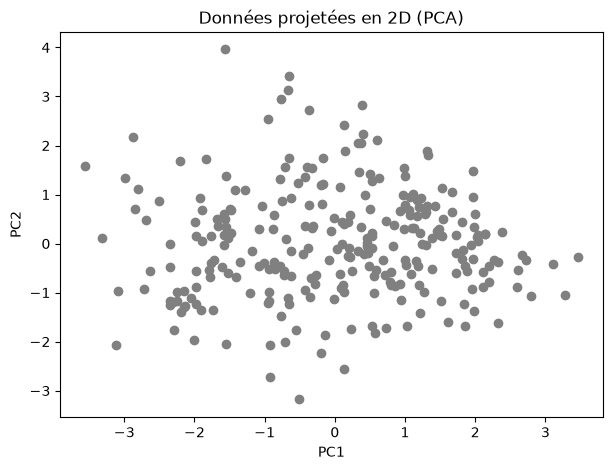

In [3]:
# PCA à 2 composantes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

part_variance = pca.explained_variance_ratio_
print(f"Variance expliquée par PC1 : {part_variance[0] * 100:.1f} %")
print(f"Variance expliquée par PC2 : {part_variance[1] * 100:.1f} %")
print(f"Total sur 2 dimensions     : {part_variance.sum() * 100:.1f} %")

# Affichage sans couleur : les points ne sont pas encore groupés
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], color="gray")
plt.title("Données projetées en 2D (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

## 4. K-Means pour k de 2 à 10

Pour chaque k, on calcule l'inertie (somme des distances au centre de cluster, à minimiser) et le coefficient de silhouette (entre -1 et 1, à maximiser).

In [4]:
# Test de K-Means pour chaque valeur de k
resultats = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM)
    etiquettes = kmeans.fit_predict(X)
    resultats.append({
        "k": k,
        "inertie": kmeans.inertia_,
        "silhouette": silhouette_score(X, etiquettes),
    })

tableau_k = pd.DataFrame(resultats)
tableau_k.round(3)

,k,inertie,silhouette
0,2,1998.633,0.165
1,3,1832.476,0.132
2,4,1734.451,0.107
3,5,1657.122,0.106
4,6,1608.168,0.100
5,7,1546.227,0.082
6,8,1501.276,0.093
7,9,1457.328,0.083
8,10,1420.172,0.086


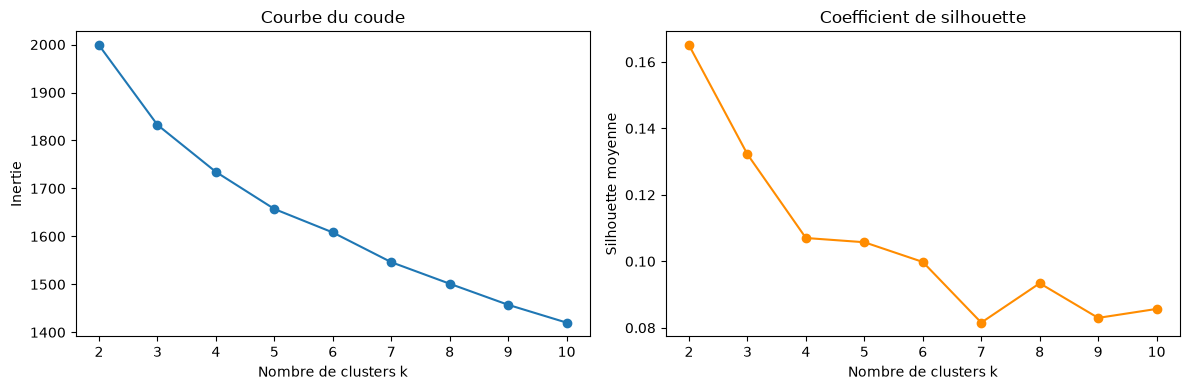

In [5]:
# Courbe du coude (inertie) et silhouette en fonction de k
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(tableau_k["k"], tableau_k["inertie"], marker="o")
ax1.set_title("Courbe du coude")
ax1.set_xlabel("Nombre de clusters k")
ax1.set_ylabel("Inertie")
ax1.set_xticks(tableau_k["k"])

ax2.plot(tableau_k["k"], tableau_k["silhouette"], marker="o", color="darkorange")
ax2.set_title("Coefficient de silhouette")
ax2.set_xlabel("Nombre de clusters k")
ax2.set_ylabel("Silhouette moyenne")
ax2.set_xticks(tableau_k["k"])

plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "courbe_coude.png", dpi=120)
plt.show()

## 5. Choix de k

- **Silhouette** : elle est maximale pour k = 2 (0,165), puis chute (0,132 pour k = 3). C'est le critère interne le plus net.
- **Courbe du coude** : l'inertie baisse régulièrement sans baisse franche. La baisse est la plus forte entre k = 2 et k = 3 (environ 166 points), le coude est donc peu lisible.
- **Qualité globale** : la silhouette reste faible (<> 0,17) pour tous les k. Les groupes se recouvrent donc beaucoup, quel que soit le k.

**Choix : k = 2**, car c'est le k qui maximise la silhouette. Il est aussi le plus simple à interpréter.

Ce choix repose uniquement sur des critères internes : `target` n'a pas été utilisée pour décider

## 6. Clustering final et visualisation

In [6]:
# Valeur de k retenue
K = 2

kmeans_final = KMeans(n_clusters=K, n_init=10, random_state=RANDOM)
clusters = kmeans_final.fit_predict(X)

print(f"Inertie pour k = {K} : {kmeans_final.inertia_:.2f}")
print(f"Silhouette pour k = {K} : {silhouette_score(X, clusters):.3f}")
print("Taille de chaque cluster :")
print(pd.Series(clusters).value_counts().sort_index())

Inertie pour k = 2 : 1998.63
Silhouette pour k = 2 : 0.165
Taille de chaque cluster :
0    124
1    146
Name: count, dtype: int64


C:\Users\Nesho\AppData\Local\Temp\ipykernel_37968\2713027770.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


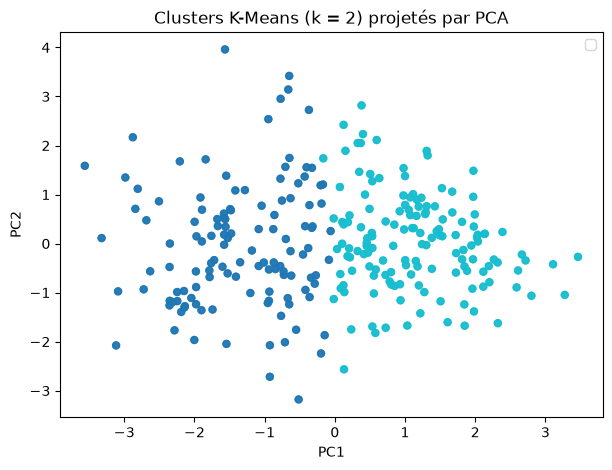

In [7]:
# Diagramme de dispersion 2D, une couleur par cluster
plt.figure(figsize=(7, 5))
for c in range(K):
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, s=25, alpha=0.8, cmap="tab10")
plt.title(f"Clusters K-Means (k = {K}) projetés par PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.savefig(DOSSIER_FIGURES / "clusters_pca.png", dpi=120)
plt.show()

## 7. Évaluation des clusters

Évaluation interne uniquement (inertie et silhouette), sans utiliser `target`.

In [8]:
# Métriques du clustering retenu
inertie_finale = kmeans_final.inertia_
silhouette_finale = silhouette_score(X, clusters)

print(f"Inertie finale    : {inertie_finale:.2f}")
print(f"Silhouette finale : {silhouette_finale:.3f}")

Inertie finale    : 1998.63
Silhouette finale : 0.165


## 8. Comparaison avec `target` (après le clustering)

Cette étape ne sert qu'à interpréter les clusters. Le modèle n'a pas été réentraîné avec `target`.

In [9]:
resume = pd.crosstab(clusters, cible, rownames=["cluster"])
resume["effectif"] = resume.sum(axis=1)
resume["% malades"] = (resume[1] / resume["effectif"] * 100).round(1)
resume

target,0,1,effectif,% malades
cluster,,,,
0,33,91,124,73.4
1,117,29,146,19.9


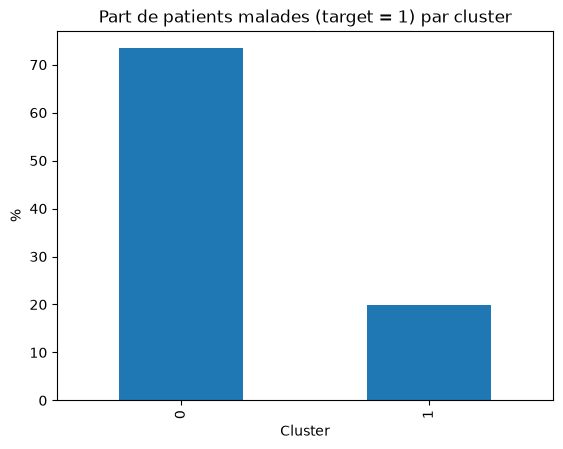

In [10]:
resume["% malades"].plot(kind="bar")
plt.title("Part de patients malades (target = 1) par cluster")
plt.xlabel("Cluster")
plt.ylabel("%")
plt.show()